# Proyecto Final de Minería de Datos
## Bank Marketing — Notebook de Modelado: 4 modelos supervisados y ajuste de hiperparámetros

**Integrantes:** Mariana Arbeláez, María Lucía Cadavid y Juan Manuel Arias

**Fuente:** [UCI Machine Learning Repository — Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing)

### Alcance de este notebook
Este notebook retoma el conjunto limpio de la Fase 1 (`bank_marketing_limpio_sin_balancear.csv`) y ejecuta:

1. Exclusión de `duration` por fuga de información (*data leakage*).
2. Partición **estratificada 80 % entrenamiento / 20 % prueba**. El 20 % se reserva y no se toca hasta la evaluación final.
3. Balanceo con **SMOTE-NC** aplicado **solo sobre el 80 % de entrenamiento** (`sampling_strategy = 0.5`).
4. Entrenamiento de **4 modelos supervisados** — Red Neuronal (MLP), Máquina de Soporte Vectorial (SVM), KNN y Árbol de Decisión — con **validación cruzada estratificada de 10 folds** sobre el 80 %.
5. Cálculo de **7 métricas** por modelo, en validación cruzada y en el 20 % de prueba.
6. **Ajuste de hiperparámetros** de los 4 modelos (incluida la proporción del SMOTE) y del **umbral de decisión**, para mejorar la ROC-AUC y la precision. La comparación final con los modelos base se hace en el 20 % de prueba.

### ¿Por qué el SMOTE va *dentro* de la validación cruzada?
Si se aplica SMOTE a todo el 80 % y **después** se hace la validación cruzada, los registros sintéticos creados a partir de un cliente pueden quedar en el fold de validación mientras el cliente original está en el de entrenamiento. El modelo se evalúa entonces con datos "parecidos a los que ya vio" y las métricas salen infladas.

Por eso el SMOTE se coloca como un paso de un `Pipeline` de `imbalanced-learn`: en cada fold se balancea **únicamente la parte de entrenamiento de ese fold**, y el fold de validación conserva la proporción real de clases (≈ 11.7 % de `yes`). Al final, el modelo definitivo se entrena con el 80 % completo balanceado y se prueba con el 20 % reservado, que nunca pasa por el SMOTE. En la sección 9 se muestra numéricamente la diferencia entre ambas formas.

## 1. Instalación e importación de librerías

In [1]:
%pip -q install imbalanced-learn scikit-learn pandas numpy matplotlib seaborn ucimlrepo

In [2]:
from pathlib import Path
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     RandomizedSearchCV, GridSearchCV)
from sklearn.base import clone
from joblib import Parallel, delayed
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, fbeta_score, roc_auc_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve,
                             precision_recall_curve)

from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline  # Pipeline de imblearn: permite SMOTE como paso

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
sns.set_theme(style="whitegrid")

# Configuración general
RANDOM_STATE = 42
TEST_SIZE = 0.20
N_FOLDS = 10
SMOTE_RATIO = 0.5   # clase 1 = 50 % del tamaño de la clase 0, solo en entrenamiento

OUTPUT_DIR = Path("entregables_preparacion_bank_marketing")

# Colores fijos por modelo (se mantienen en todas las gráficas)
COLORES = {"Red Neuronal (MLP)": "#2a78d6", "SVM": "#eb6834",
           "KNN": "#1baf7a", "Árbol de Decisión": "#eda100",
           "Línea base (clase mayoritaria)": "#8a8984"}

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


## 2. Carga del dataset limpio
Se busca el archivo exportado por el notebook `01_Preparacion_Datos_Bank_Marketing`. Si no se encuentra (por ejemplo, al ejecutar en una sesión nueva de Colab), se descarga desde UCI y se aplica la misma limpieza del notebook 01 (normalización de texto y eliminación de duplicados exactos).

In [3]:
rutas_posibles = [
    OUTPUT_DIR / "bank_marketing_limpio_sin_balancear.csv",
    Path("bank_marketing_limpio_sin_balancear.csv"),
    Path("/content/bank_marketing_limpio_sin_balancear.csv"),
]
input_path = next((p for p in rutas_posibles if p.exists()), None)

if input_path is not None:
    df = pd.read_csv(input_path)
    print("Dataset limpio cargado desde:", input_path)
else:
    from ucimlrepo import fetch_ucirepo
    bank = fetch_ucirepo(id=222)
    df = pd.concat([bank.data.features, bank.data.targets], axis=1)
    for col in df.select_dtypes(exclude="number").columns:
        df[col] = df[col].astype("string").str.strip()
    df = df.drop_duplicates().reset_index(drop=True)
    print("No se encontró el CSV limpio: se descargó desde UCI y se aplicó la limpieza del notebook 01.")

print("Dimensiones:", df.shape)
display(df.head())

Dataset limpio cargado desde: entregables_preparacion_bank_marketing/bank_marketing_limpio_sin_balancear.csv
Dimensiones: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


## 3. Exclusión de la variable `duration` (fuga de información)
`duration` es la duración de la última llamada. Solo se conoce **después** de llamar al cliente, y el objetivo del proyecto es priorizar clientes **antes** de la llamada. Incluirla elevaría artificialmente el desempeño (una llamada de 0 segundos implica `y = no`) y haría inútil el modelo en producción.

In [4]:
df = df.drop(columns=["duration"], errors="ignore")
print("Dimensiones sin 'duration':", df.shape)

Dimensiones sin 'duration': (45211, 16)


## 4. Variables predictoras, variable objetivo y valores "unknown"
En la fuente original las categorías desconocidas vienen como el texto `"unknown"`; la librería `ucimlrepo` las convierte en `NaN`. Siguiendo lo definido en la fase de preparación (sección 3.5 del documento CRISP-DM), **no se eliminan registros**: se restaura `"unknown"` como una categoría propia. Esto es especialmente importante en `poutcome` (81.7 % sin campaña previa) y `contact` (28.8 %), donde la ausencia de dato es informativa.

In [5]:
X = df.drop(columns=["y"])
y = (df["y"].astype(str).str.strip().str.lower() == "yes").astype(int)

categorical_features = X.select_dtypes(exclude="number").columns.tolist()
numeric_features = X.select_dtypes(include="number").columns.tolist()

X[categorical_features] = X[categorical_features].fillna("unknown").astype(str)

print("Variables numéricas  :", numeric_features)
print("Variables categóricas:", categorical_features)
print("Faltantes restantes  :", int(X.isna().sum().sum()))
print("\nDistribución de y (%):")
print((y.value_counts(normalize=True) * 100).round(2).rename({0: "no (0)", 1: "yes (1)"}))

Variables numéricas  : ['age', 'balance', 'day_of_week', 'campaign', 'pdays', 'previous']
Variables categóricas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Faltantes restantes  : 0

Distribución de y (%):
y
no (0)     88.3
yes (1)    11.7
Name: proportion, dtype: float64


## 5. Partición estratificada 80 % / 20 %
Como la clase positiva es apenas ≈ 11.7 %, la partición se **estratifica** por `y` para que entrenamiento y prueba conserven la misma proporción. El 20 % de prueba queda reservado: no participa en el SMOTE, ni en la validación cruzada, ni en ninguna decisión de configuración.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)

resumen_particion = pd.DataFrame({
    "registros": [len(y_train), len(y_test)],
    "clase 0 (no)": [int((y_train == 0).sum()), int((y_test == 0).sum())],
    "clase 1 (yes)": [int((y_train == 1).sum()), int((y_test == 1).sum())],
    "% clase 1": [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)],
}, index=["Entrenamiento (80 %)", "Prueba (20 %)"])
display(resumen_particion)

,registros,clase 0 (no),clase 1 (yes),% clase 1
Entrenamiento (80 %),36168,31937,4231,11.7
Prueba (20 %),9043,7985,1058,11.7


## 6. Balanceo con SMOTE-NC sobre el 80 % de entrenamiento
Se usa **SMOTE-NC** (*SMOTE for Nominal and Continuous*) en lugar de SMOTE clásico porque el dataset tiene 9 variables categóricas. El SMOTE clásico aplicado sobre columnas one-hot genera valores imposibles (por ejemplo `job_admin = 0.37`); SMOTE-NC interpola solo las numéricas y asigna a las categóricas el valor más frecuente entre los vecinos, de modo que cada registro sintético es un cliente válido.

`sampling_strategy = 0.5` lleva la clase minoritaria al 50 % del tamaño de la mayoritaria (proporción final ≈ 67 % / 33 %). Se eligió un balanceo parcial, y no 50/50, para no inventar demasiados registros sintéticos (sería más del triple de positivos reales) y no sesgar excesivamente los modelos hacia la clase `yes`.

La celda siguiente muestra el efecto del SMOTE sobre el 80 % completo, que es exactamente lo que recibe cada modelo en su entrenamiento final. Durante la validación cruzada el mismo paso se aplica dentro de cada fold.

In [7]:
def crear_smote():
    return SMOTENC(categorical_features=categorical_features,
                   sampling_strategy=SMOTE_RATIO, random_state=RANDOM_STATE)

X_train_bal, y_train_bal = crear_smote().fit_resample(X_train, y_train)

def conteo(y_):
    return {"clase 0 (no)": int((y_ == 0).sum()), "clase 1 (yes)": int((y_ == 1).sum()),
            "total": len(y_), "% clase 1": round(float(np.mean(y_)) * 100, 2)}

efecto_smote = pd.DataFrame([conteo(y_train), conteo(y_train_bal)],
                            index=["Antes del SMOTE", "Después del SMOTE"])
display(efecto_smote)
print(f"Registros sintéticos generados: {len(y_train_bal) - len(y_train):,}")

,clase 0 (no),clase 1 (yes),total,% clase 1
Antes del SMOTE,31937,4231,36168,11.70
Después del SMOTE,31937,15968,47905,33.33


Registros sintéticos generados: 11,737


## 7. Preprocesamiento y definición de los 4 modelos
**Preprocesamiento (ajustado solo con datos de entrenamiento en cada fold):**
- Numéricas (`age`, `balance`, `day_of_week`, `campaign`, `pdays`, `previous`): `StandardScaler`. Es indispensable para la red neuronal, la SVM y KNN, que dependen de distancias o de gradientes. Al árbol no le afecta.
- Categóricas: `OneHotEncoder(handle_unknown="ignore")`.

**Pipeline de cada modelo:** `SMOTE-NC → preprocesamiento → clasificador`.

**Configuración de parámetros.** Son configuraciones base razonables para este tamaño de datos, verificadas con una prueba rápida sobre el entrenamiento. En la sección 11 se ajustan con una búsqueda de hiperparámetros.

| Modelo | Parámetros | Justificación |
|---|---|---|
| Red Neuronal (MLP) | 1 capa oculta de 32 neuronas, `relu`, `adam`, `alpha = 0.01` (L2), `early_stopping = True` (10 % de validación interna), `max_iter = 300` | Red pequeña para ≈ 50 entradas; la regularización L2 y la parada temprana evitan el sobreajuste. |
| SVM | `kernel = "rbf"`, `C = 1.0`, `gamma = "scale"` | El kernel RBF captura relaciones no lineales; `C = 1` es un margen moderado. Se usa `decision_function` para ROC-AUC (no requiere `probability = True`, que multiplicaría el tiempo). |
| KNN | `n_neighbors = 51`, `weights = "distance"`, distancia euclidiana | Con ≈ 43 000 registros de entrenamiento por fold, un k pequeño es muy ruidoso; k = 51 suaviza la frontera y la ponderación por distancia da más peso a los vecinos cercanos. |
| Árbol de Decisión | `criterion = "gini"`, `max_depth = 10`, `min_samples_leaf = 100` | La profundidad máxima y el mínimo de registros por hoja controlan el sobreajuste y mantienen el árbol interpretable. |

In [8]:
preprocesador = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

modelos = {
    "Red Neuronal (MLP)": MLPClassifier(
        hidden_layer_sizes=(32,), activation="relu", solver="adam", alpha=0.01,
        early_stopping=True, validation_fraction=0.1, max_iter=300,
        random_state=RANDOM_STATE),
    "SVM": SVC(kernel="rbf", C=1.0, gamma="scale", cache_size=1000,
               random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=51, weights="distance", metric="minkowski", p=2),
    "Árbol de Decisión": DecisionTreeClassifier(
        criterion="gini", max_depth=10, min_samples_leaf=100, random_state=RANDOM_STATE),
}

def construir_pipeline(clasificador, con_smote=True):
    pasos = [("smote", crear_smote())] if con_smote else []
    pasos += [("preprocesamiento", preprocesador), ("modelo", clasificador)]
    return Pipeline(pasos)

construir_pipeline(modelos["Red Neuronal (MLP)"])

,steps,"[('smote', ...), ('preprocesamiento', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,categorical_features,"['job', 'marital', ...]"
,sampling_strategy,0.5
,random_state,42
,categorical_encoder,None
,k_neighbors,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'


## 8. Validación cruzada estratificada (10 folds) sobre el 80 %
**Esquema:** `StratifiedKFold(n_splits = 10, shuffle = True, random_state = 42)`. Se usan **los mismos 10 folds para todos los modelos**. Así, las diferencias entre modelos se deben al algoritmo y no a la partición.

**Métricas (7).** La clase positiva es `yes` (1):

| Métrica | Qué mide | Por qué importa aquí |
|---|---|---|
| Accuracy | % total de aciertos | Engañosa con desbalance: predecir siempre `no` da 88 %. Se reporta solo como referencia. |
| Balanced accuracy | Promedio del recall de cada clase | Corrige el desbalance; 0.5 equivale al azar. |
| Precision | De los clientes que el modelo marca `yes`, cuántos contratan | Eficiencia de la campaña: llamadas que terminan en contratación. |
| Recall (sensibilidad) | De los que sí contratan, cuántos detecta el modelo | Oportunidades de negocio que no se pierden. |
| F1 | Media armónica de precision y recall | Resume el equilibrio entre ambas; **métrica principal** para comparar. |
| ROC-AUC | Capacidad de ordenar positivos sobre negativos, en todos los umbrales | Independiente del umbral; útil para priorizar clientes por puntaje. |
| PR-AUC (average precision) | Área bajo la curva precisión-recall | Más exigente que ROC-AUC con clases desbalanceadas; su línea base es 0.117 (la prevalencia). |

Precision, recall, F1 y las dos accuracies se calculan con el umbral por defecto (probabilidad 0.5; en la SVM, `decision_function = 0`).

Como referencia se incluye una **línea base** que siempre predice la clase mayoritaria (`DummyClassifier`), tal como se definió en la sección 1.5 del documento CRISP-DM.

> ⏱️ La SVM es el modelo más lento (≈ 1 minuto por fold). La celda completa puede tardar entre 5 y 15 minutos según el equipo.

In [9]:
METRICAS = {
    "accuracy": "Accuracy",
    "balanced_accuracy": "Balanced accuracy",
    "precision": "Precision",
    "recall": "Recall",
    "f1": "F1",
    "roc_auc": "ROC-AUC",
    "average_precision": "PR-AUC",
}
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

def evaluar_cv(nombre, clasificador, con_smote=True):
    # Validación cruzada con el SMOTE dentro de cada fold. Devuelve una fila por fold.
    pipe = construir_pipeline(clasificador, con_smote=con_smote)
    inicio = time.time()
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=list(METRICAS),
                         n_jobs=-1, error_score="raise")
    filas = pd.DataFrame({METRICAS[m]: res[f"test_{m}"] for m in METRICAS})
    filas["Tiempo de entrenamiento (s)"] = res["fit_time"]
    filas.insert(0, "Fold", range(1, N_FOLDS + 1))
    filas.insert(0, "Modelo", nombre)
    print(f"{nombre:<32} listo en {time.time() - inicio:6.1f} s  |  "
          f"F1 = {filas['F1'].mean():.3f}  ROC-AUC = {filas['ROC-AUC'].mean():.3f}")
    return filas

resultados_folds = [evaluar_cv("Línea base (clase mayoritaria)",
                               DummyClassifier(strategy="most_frequent"), con_smote=False)]
for nombre, clf in modelos.items():
    resultados_folds.append(evaluar_cv(nombre, clf))

cv_folds = pd.concat(resultados_folds, ignore_index=True)

Línea base (clase mayoritaria)   listo en    2.1 s  |  F1 = 0.000  ROC-AUC = 0.500


Red Neuronal (MLP)               listo en   38.6 s  |  F1 = 0.429  ROC-AUC = 0.763


SVM                              listo en  371.9 s  |  F1 = 0.452  ROC-AUC = 0.758


KNN                              listo en   23.3 s  |  F1 = 0.415  ROC-AUC = 0.761


Árbol de Decisión                listo en   13.1 s  |  F1 = 0.431  ROC-AUC = 0.749


### 8.1 Tabla comparativa — validación cruzada (media ± desviación estándar de los 10 folds)

In [10]:
columnas_metricas = list(METRICAS.values()) + ["Tiempo de entrenamiento (s)"]
orden_modelos = list(modelos) + ["Línea base (clase mayoritaria)"]

cv_media = cv_folds.groupby("Modelo")[columnas_metricas].mean().reindex(orden_modelos)
cv_std = cv_folds.groupby("Modelo")[columnas_metricas].std().reindex(orden_modelos)

tabla_cv = cv_media.copy().astype(object)
for col in METRICAS.values():
    tabla_cv[col] = [f"{m:.3f} ± {d:.3f}" for m, d in zip(cv_media[col], cv_std[col])]
tabla_cv["Tiempo de entrenamiento (s)"] = cv_media["Tiempo de entrenamiento (s)"].map("{:.1f}".format)
tabla_cv = tabla_cv.sort_values("Modelo", key=lambda s: s.map(lambda m: -cv_media.loc[m, "F1"]))
display(tabla_cv)

,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Tiempo de entrenamiento (s)
Modelo,,,,,,,,
SVM,0.871 ± 0.005,0.691 ± 0.014,0.451 ± 0.020,0.455 ± 0.031,0.452 ± 0.020,0.758 ± 0.017,0.399 ± 0.024,64.3
Árbol de Decisión,0.851 ± 0.005,0.692 ± 0.016,0.391 ± 0.013,0.483 ± 0.039,0.431 ± 0.019,0.749 ± 0.010,0.367 ± 0.020,2.5
Red Neuronal (MLP),0.855 ± 0.006,0.686 ± 0.009,0.399 ± 0.017,0.464 ± 0.022,0.429 ± 0.014,0.763 ± 0.013,0.398 ± 0.022,7.3
KNN,0.852 ± 0.005,0.677 ± 0.012,0.386 ± 0.016,0.448 ± 0.024,0.415 ± 0.017,0.761 ± 0.013,0.382 ± 0.024,2.3
Línea base (clase mayoritaria),0.883 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.117 ± 0.000,0.1


**Interpretación de la validación cruzada**

- **Todos los modelos superan con claridad a la línea base.** Predecir siempre `no` da 88.3 % de accuracy, pero F1 = 0, balanced accuracy = 0.5 y PR-AUC = 0.117. Los 4 modelos alcanzan una PR-AUC de entre 0.37 y 0.40, más del triple de la línea base.
- **Que la accuracy de los modelos (0.85–0.87) sea menor que la de la línea base es esperable.** El SMOTE desplaza las decisiones hacia `yes`: se aceptan algunos falsos positivos a cambio de detectar clientes que sí contratan. Por eso la accuracy no se usa para comparar.
- **SVM** obtiene el mejor F1 (0.452) y la mejor precision (0.451). Es el modelo más equilibrado entre precision y recall, pero también el más costoso: ≈ 46 s de entrenamiento por fold, frente a 1–4 s de los demás.
- **Red Neuronal (MLP)** tiene la mejor ROC-AUC (0.763) y empata con la SVM en PR-AUC (≈ 0.40). Es decir, es la que mejor **ordena** a los clientes por probabilidad de contratar, aunque con el umbral de 0.5 su F1 (0.429) es menor que el de la SVM.
- **Árbol de Decisión** tiene el mayor recall (0.483), es decir, encuentra más clientes que contratan, pero con una precision baja (0.391) y las menores ROC-AUC (0.749) y PR-AUC (0.367). Su capacidad de ordenar es la más débil.
- **KNN** tiene el F1 más bajo (0.415) y la menor precision (0.386), pero una ROC-AUC (0.761) muy cercana a la de la MLP.
- **Las diferencias son pequeñas y la variación entre folds es comparable.** Las desviaciones estándar van de 0.01 a 0.04 y los rangos de los boxplots se solapan. En ROC-AUC, por ejemplo, los cuatro modelos están entre 0.749 y 0.763. A simple vista, la SVM destaca en F1 y el árbol queda por debajo en PR-AUC, pero las diferencias entre modelos son del mismo orden que la variación entre folds.

### 8.2 Variabilidad entre folds

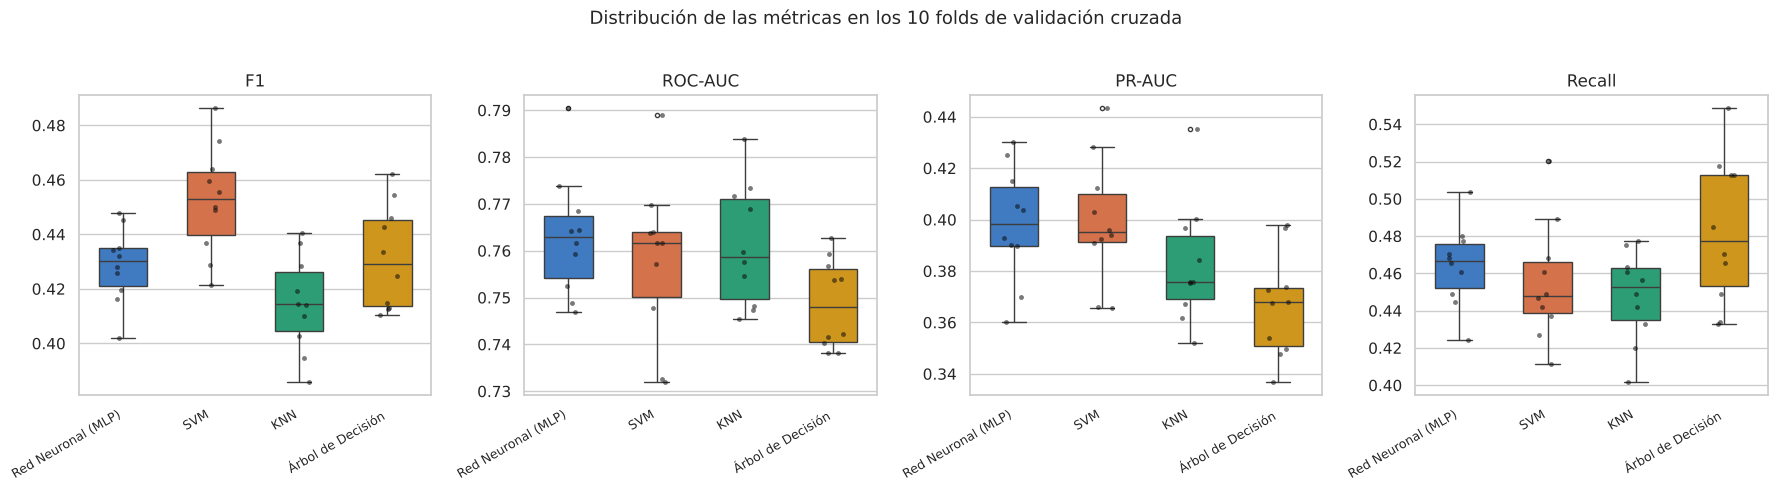

In [11]:
metricas_grafica = ["F1", "ROC-AUC", "PR-AUC", "Recall"]
datos_graf = cv_folds[cv_folds["Modelo"].isin(modelos)]

fig, axes = plt.subplots(1, len(metricas_grafica), figsize=(18, 4.8))
for ax, met in zip(axes, metricas_grafica):
    sns.boxplot(data=datos_graf, x="Modelo", y=met, order=list(modelos),
                palette=[COLORES[m] for m in modelos], width=0.55, fliersize=3,
                linewidth=1, ax=ax)
    sns.stripplot(data=datos_graf, x="Modelo", y=met, order=list(modelos),
                  color="#0b0b0b", size=3.5, alpha=0.55, jitter=0.12, ax=ax)
    ax.set_title(met, fontsize=12)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=30, labelsize=9)
    for lbl in ax.get_xticklabels():
        lbl.set_ha("right")
fig.suptitle("Distribución de las métricas en los 10 folds de validación cruzada", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

## 9. Comprobación: ¿qué pasa si el SMOTE se aplica *antes* de la validación cruzada?
Para justificar el diseño, se repite la validación cruzada del Árbol de Decisión (el modelo más rápido) de la forma incorrecta: aplicando SMOTE al 80 % completo y haciendo la validación cruzada sobre los datos ya balanceados.

In [12]:
arbol = modelos["Árbol de Decisión"]

# Forma incorrecta: SMOTE sobre todo el 80 % y luego CV (la validación contiene registros sintéticos)
res_incorrecto = cross_validate(construir_pipeline(arbol, con_smote=False),
                                X_train_bal, y_train_bal, cv=cv,
                                scoring=list(METRICAS), n_jobs=-1)
incorrecto = pd.Series({METRICAS[m]: res_incorrecto[f"test_{m}"].mean() for m in METRICAS})
correcto = cv_media.loc["Árbol de Decisión", list(METRICAS.values())]

comparacion_smote = pd.DataFrame({
    "SMOTE antes de la CV (incorrecto)": incorrecto,
    "SMOTE dentro de cada fold (correcto)": correcto,
}).round(3)
comparacion_smote["Diferencia"] = (comparacion_smote.iloc[:, 0] - comparacion_smote.iloc[:, 1]).round(3)
display(comparacion_smote)

,SMOTE antes de la CV (incorrecto),SMOTE dentro de cada fold (correcto),Diferencia
Accuracy,0.798,0.851,-0.053
Balanced accuracy,0.751,0.692,0.059
Precision,0.741,0.391,0.350
Recall,0.609,0.483,0.126
F1,0.668,0.431,0.237
ROC-AUC,0.842,0.749,0.093
PR-AUC,0.737,0.367,0.370


**Interpretación.** Con el SMOTE aplicado antes de la validación cruzada, el mismo árbol parece mucho mejor: F1 de 0.668 frente a 0.431 y PR-AUC de 0.737 frente a 0.367. Esa mejora es **falsa** por dos razones:
1. Hay registros sintéticos en los folds de validación que fueron generados a partir de clientes del fold de entrenamiento.
2. Los folds de validación tienen 33 % de positivos, cuando la realidad (y el conjunto de prueba) tiene 11.7 %.

Si se hubiera reportado esa cifra, el modelo habría decepcionado al evaluarlo en el 20 % de prueba. Con el SMOTE dentro de cada fold, la CV estima bien el desempeño en prueba, como se ve en la sección 10.4.

## 10. Evaluación final en el 20 % de prueba
Cada pipeline se entrena con **todo el 80 %** (SMOTE-NC → preprocesamiento → modelo) y se evalúa una sola vez sobre el 20 % reservado, que conserva la distribución real (11.7 % de `yes`) y nunca pasó por el SMOTE.

In [13]:
def puntaje(pipe, X_):
    # Probabilidad de la clase 1, o decision_function en la SVM
    if hasattr(pipe, "predict_proba") and not isinstance(pipe.named_steps["modelo"], SVC):
        return pipe.predict_proba(X_)[:, 1]
    return pipe.decision_function(X_)

def metricas_prueba(y_true, y_pred, y_score):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_score),
        "PR-AUC": average_precision_score(y_true, y_score),
    }

pipelines_finales, predicciones, puntajes, filas_test = {}, {}, {}, []

base = construir_pipeline(DummyClassifier(strategy="most_frequent"), con_smote=False).fit(X_train, y_train)
filas_test.append({"Modelo": "Línea base (clase mayoritaria)",
                   **metricas_prueba(y_test, base.predict(X_test), base.predict_proba(X_test)[:, 1]),
                   "Tiempo de entrenamiento (s)": np.nan})

for nombre, clf in modelos.items():
    pipe = construir_pipeline(clf)
    inicio = time.time()
    pipe.fit(X_train, y_train)
    t_fit = time.time() - inicio
    y_pred, y_score = pipe.predict(X_test), puntaje(pipe, X_test)
    pipelines_finales[nombre], predicciones[nombre], puntajes[nombre] = pipe, y_pred, y_score
    filas_test.append({"Modelo": nombre, **metricas_prueba(y_test, y_pred, y_score),
                       "Tiempo de entrenamiento (s)": t_fit})
    print(f"{nombre:<20} entrenado en {t_fit:5.1f} s")

tabla_test = pd.DataFrame(filas_test).set_index("Modelo")
tabla_test = pd.concat([tabla_test.loc[list(modelos)].sort_values("F1", ascending=False),
                        tabla_test.loc[["Línea base (clase mayoritaria)"]]])

Red Neuronal (MLP)   entrenado en   8.4 s


SVM                  entrenado en  85.8 s


KNN                  entrenado en   2.6 s


Árbol de Decisión    entrenado en   3.0 s


### 10.1 Tabla de desempeño de los 4 modelos en el 20 % de prueba

In [14]:
(tabla_test.style
    .format({c: "{:.3f}" for c in METRICAS.values()} | {"Tiempo de entrenamiento (s)": "{:.1f}"}, na_rep="—")
    .highlight_max(subset=pd.IndexSlice[list(modelos), ["Balanced accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]],
                   color="#d6e6f8")
    .set_caption("Métricas sobre el conjunto de prueba (9 043 clientes, 1 058 positivos). En azul, el mejor de los 4 modelos por métrica."))

,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Tiempo de entrenamiento (s)
Modelo,,,,,,,,
SVM,0.874,0.698,0.463,0.467,0.465,0.768,0.412,85.8
Red Neuronal (MLP),0.864,0.691,0.424,0.465,0.444,0.771,0.414,8.4
KNN,0.855,0.688,0.398,0.469,0.431,0.775,0.406,2.6
Árbol de Decisión,0.836,0.703,0.363,0.528,0.430,0.761,0.384,3.0
Línea base (clase mayoritaria),0.883,0.500,0.000,0.000,0.000,0.500,0.117,—


### 10.2 Matrices de confusión (prueba)

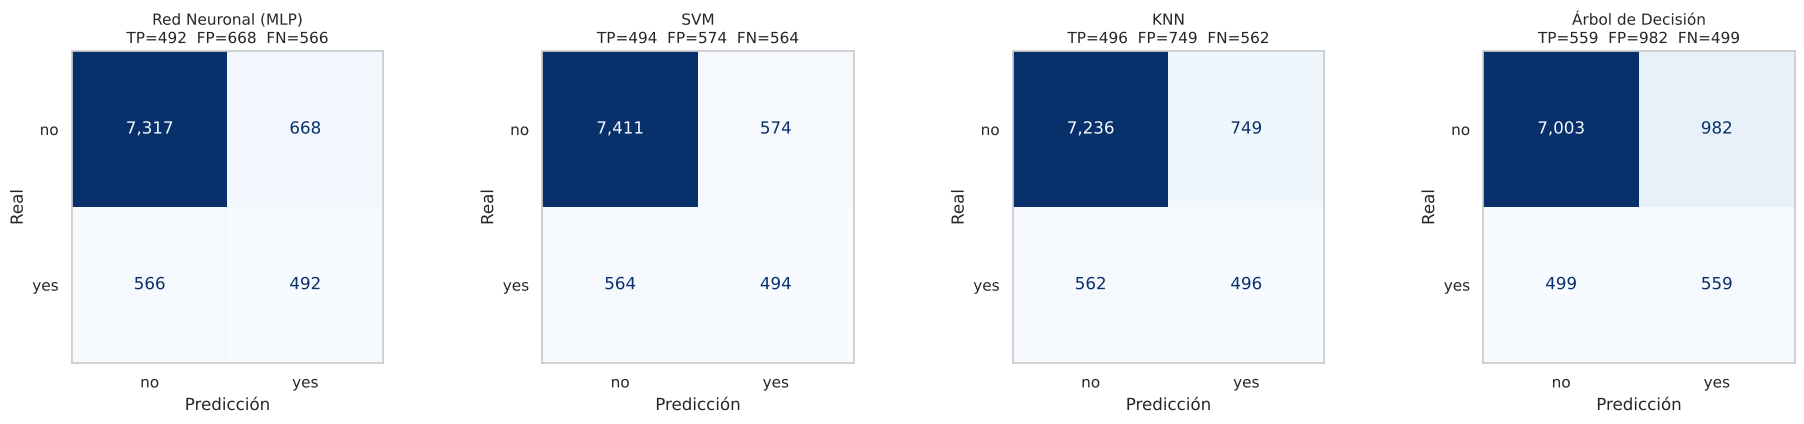

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.3))
for ax, nombre in zip(axes, modelos):
    cm = confusion_matrix(y_test, predicciones[nombre])
    ConfusionMatrixDisplay(cm, display_labels=["no", "yes"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=",")
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f"{nombre}\nTP={tp:,}  FP={fp:,}  FN={fn:,}", fontsize=11)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Real")
    ax.grid(False)
plt.tight_layout()
plt.show()

### 10.3 Curvas ROC y Precisión-Recall (prueba)

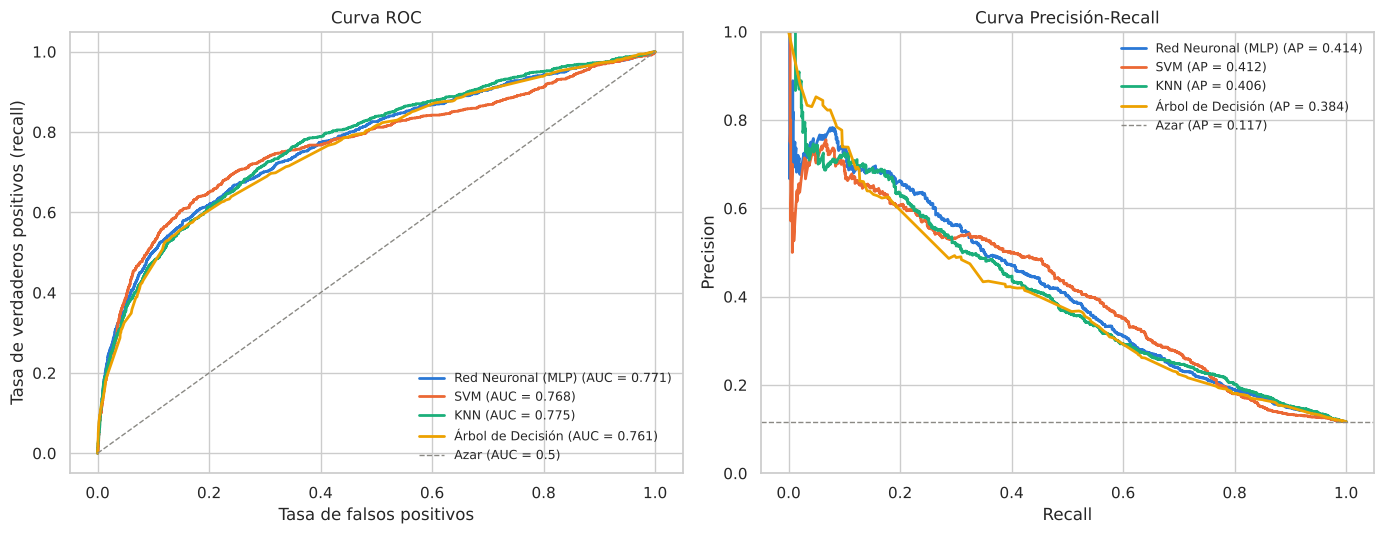

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
prevalencia = y_test.mean()

for nombre in modelos:
    fpr, tpr, _ = roc_curve(y_test, puntajes[nombre])
    ax1.plot(fpr, tpr, lw=2, color=COLORES[nombre],
             label=f"{nombre} (AUC = {tabla_test.loc[nombre, 'ROC-AUC']:.3f})")
    prec, rec, _ = precision_recall_curve(y_test, puntajes[nombre])
    ax2.plot(rec, prec, lw=2, color=COLORES[nombre],
             label=f"{nombre} (AP = {tabla_test.loc[nombre, 'PR-AUC']:.3f})")

ax1.plot([0, 1], [0, 1], ls="--", lw=1, color="#8a8984", label="Azar (AUC = 0.5)")
ax1.set(title="Curva ROC", xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos (recall)")
ax2.axhline(prevalencia, ls="--", lw=1, color="#8a8984", label=f"Azar (AP = {prevalencia:.3f})")
ax2.set(title="Curva Precisión-Recall", xlabel="Recall", ylabel="Precision", ylim=(0, 1))
for ax in (ax1, ax2):
    ax.legend(loc="best", fontsize=9, frameon=False)
plt.tight_layout()
plt.show()

### 10.4 Validación cruzada vs. prueba (F1 y ROC-AUC)

In [17]:
cv_vs_test = pd.DataFrame({
    "F1 (CV)": cv_media.loc[list(modelos), "F1"],
    "F1 (prueba)": tabla_test.loc[list(modelos), "F1"],
    "ROC-AUC (CV)": cv_media.loc[list(modelos), "ROC-AUC"],
    "ROC-AUC (prueba)": tabla_test.loc[list(modelos), "ROC-AUC"],
}).round(3)
cv_vs_test["Diferencia F1"] = (cv_vs_test["F1 (prueba)"] - cv_vs_test["F1 (CV)"]).round(3)
display(cv_vs_test.sort_values("F1 (prueba)", ascending=False))

,F1 (CV),F1 (prueba),ROC-AUC (CV),ROC-AUC (prueba),Diferencia F1
Modelo,,,,,
SVM,0.452,0.465,0.758,0.768,0.013
Red Neuronal (MLP),0.429,0.444,0.763,0.771,0.015
KNN,0.415,0.431,0.761,0.775,0.016
Árbol de Decisión,0.431,0.430,0.749,0.761,-0.001


**Interpretación de la evaluación en el 20 % de prueba**

- **Los resultados de prueba confirman los de validación cruzada.** La diferencia en F1 entre CV y prueba es de 0.016 o menos en los 4 modelos, y el orden se mantiene. No hay señales de sobreajuste, y la estimación de la CV, con el SMOTE dentro de cada fold, fue confiable.
- **SVM:** mejor F1 (0.465) y mejor precision (0.463). De los 1 068 clientes que marca como `yes`, 494 contratan, es decir, el 46 %, frente al 11.7 % que se obtendría llamando al azar (≈ 4 veces más efectivo). Detecta el 47 % de los clientes que contratan (494 de 1 058).
- **Red Neuronal (MLP):** segundo F1 (0.444) y la mejor PR-AUC (0.414). Ofrece un desempeño muy parecido al de la SVM, con un tiempo de entrenamiento unas 10 veces menor.
- **KNN:** la mejor ROC-AUC en prueba (0.775), pero F1 de 0.431 por su menor precision (0.398).
- **Árbol de Decisión:** el mayor recall (0.528: detecta 559 de 1 058 clientes que contratan) y la mejor balanced accuracy (0.703), a costa de 982 falsos positivos, el mayor número de llamadas sin éxito. Su ventaja adicional es la interpretabilidad.
- **Capacidad de ordenar:** las ROC-AUC (0.761–0.775) y las PR-AUC (0.384–0.414) están muy próximas. Las diferencias en precision y recall se deben en buena parte al **umbral de decisión de 0.5**: si el banco prioriza encontrar más clientes (recall) o hacer menos llamadas inútiles (precision), el umbral puede ajustarse (sección 13).
- **Desempeño moderado en general:** sin `duration`, las variables disponibles antes de la llamada separan las clases solo parcialmente (ROC-AUC ≈ 0.77). Es una consecuencia del planteamiento pre-llamada, que es el realista para el negocio.

## 11. Ajuste de hiperparámetros
**Objetivo:** mejorar la **ROC-AUC** (capacidad de ordenar a los clientes) y la **precision** (de los clientes que el modelo recomienda llamar, cuántos contratan).

Estas dos métricas responden a cosas distintas, por eso se trabajan con dos palancas:
1. **Hiperparámetros del modelo y proporción del SMOTE → ROC-AUC.** La ROC-AUC no depende del umbral, así que mide la calidad del puntaje. La mejor configuración de cada modelo se busca con validación cruzada **solo sobre el 80 % de entrenamiento**.
2. **Umbral de decisión → precision** (sección 13). Subir el umbral hace que el modelo marque `yes` solo a los clientes más seguros: **aumenta la precision a costa del recall**.

**Búsqueda:**
- **Red Neuronal, KNN y Árbol:** `RandomizedSearchCV` con validación cruzada estratificada de 5 folds.
- **SVM:** `GridSearchCV` con 3 folds, porque cada entrenamiento tarda ≈ 25 s.
- La proporción del SMOTE (`smote__sampling_strategy`) se incluye como un hiperparámetro más.
- Se registran precision, PR-AUC, F1 y recall de cada combinación, pero **la ganadora se elige por ROC-AUC**.

| Modelo | Hiperparámetros explorados |
|---|---|
| Red Neuronal (MLP) | `hidden_layer_sizes`: (16,), (32,), (64,), (32,16), (64,32) · `alpha`: 0.0001 – 1 · `learning_rate_init`: 0.001, 0.003 · SMOTE: 0.25, 0.5, 0.75, 1.0 · 30 combinaciones |
| SVM | `C`: 0.3, 1, 3 · `gamma`: 0.01, 0.03, "scale" · SMOTE: 0.25, 0.5 · 18 combinaciones (grilla completa) |
| KNN | `n_neighbors`: 51 – 301 · `weights`: uniform, distance · `p`: 1 (Manhattan), 2 (euclidiana) · SMOTE: 0.25 – 1.0 · 25 combinaciones |
| Árbol de Decisión | `max_depth`: 4 – 15 o sin límite · `min_samples_leaf`: 20 – 800 · `criterion`: gini, entropy · SMOTE: 0.25 – 1.0 · 60 combinaciones |

> ⏱️ La búsqueda completa tarda unos 40 minutos (la SVM ≈ 17). Para volver a ejecutar el notebook sin repetirla, ponga `EJECUTAR_BUSQUEDA = False`: se usarán los hiperparámetros ganadores ya encontrados, que están escritos en la celda.

In [18]:
EJECUTAR_BUSQUEDA = True
N_FOLDS_BUSQUEDA = 5
SMOTE_OPCIONES = [0.25, 0.5, 0.75, 1.0]

espacios = {
    "Red Neuronal (MLP)": dict(
        busqueda="random", n_iter=30, folds=N_FOLDS_BUSQUEDA,
        modelo=MLPClassifier(early_stopping=True, max_iter=300, random_state=RANDOM_STATE),
        grilla={"modelo__hidden_layer_sizes": [(16,), (32,), (64,), (32, 16), (64, 32)],
                "modelo__alpha": [1e-4, 1e-3, 1e-2, 1e-1, 1.0],
                "modelo__learning_rate_init": [1e-3, 3e-3],
                "smote__sampling_strategy": SMOTE_OPCIONES}),
    "SVM": dict(
        busqueda="grid", folds=3,
        modelo=SVC(kernel="rbf", cache_size=1000, random_state=RANDOM_STATE),
        grilla={"modelo__C": [0.3, 1, 3],
                "modelo__gamma": [0.01, 0.03, "scale"],
                "smote__sampling_strategy": [0.25, 0.5]}),
    "KNN": dict(
        busqueda="random", n_iter=25, folds=N_FOLDS_BUSQUEDA,
        modelo=KNeighborsClassifier(),
        grilla={"modelo__n_neighbors": [51, 101, 151, 201, 301],
                "modelo__weights": ["uniform", "distance"],
                "modelo__p": [1, 2],
                "smote__sampling_strategy": SMOTE_OPCIONES}),
    "Árbol de Decisión": dict(
        busqueda="random", n_iter=60, folds=N_FOLDS_BUSQUEDA,
        modelo=DecisionTreeClassifier(random_state=RANDOM_STATE),
        grilla={"modelo__max_depth": [4, 6, 8, 10, 12, 15, None],
                "modelo__min_samples_leaf": [20, 50, 100, 200, 400, 800],
                "modelo__criterion": ["gini", "entropy"],
                "smote__sampling_strategy": SMOTE_OPCIONES}),
}

# Resultado de la búsqueda (se usa solo si EJECUTAR_BUSQUEDA = False)
MEJORES_PARAMS_ENCONTRADOS = {
    "Red Neuronal (MLP)": {"modelo__hidden_layer_sizes": (64, 32), "modelo__alpha": 0.1,
                           "modelo__learning_rate_init": 0.001, "smote__sampling_strategy": 0.25},
    "SVM": {"modelo__C": 0.3, "modelo__gamma": 0.03, "smote__sampling_strategy": 0.5},
    "KNN": {"modelo__n_neighbors": 301, "modelo__weights": "distance", "modelo__p": 1,
            "smote__sampling_strategy": 0.25},
    "Árbol de Decisión": {"modelo__max_depth": 10, "modelo__min_samples_leaf": 50,
                          "modelo__criterion": "gini", "smote__sampling_strategy": 0.25},
}
SCORING = {"ROC-AUC": "roc_auc", "Precision": "precision", "PR-AUC": "average_precision",
           "F1": "f1", "Recall": "recall"}

In [19]:
mejores_params, tablas_busqueda = {}, {}

if EJECUTAR_BUSQUEDA:
    for nombre, e in espacios.items():
        cv_busqueda = StratifiedKFold(n_splits=e["folds"], shuffle=True, random_state=RANDOM_STATE)
        kw = dict(scoring=SCORING, refit=False, cv=cv_busqueda, n_jobs=-1)
        if e["busqueda"] == "random":
            buscador = RandomizedSearchCV(construir_pipeline(e["modelo"]), e["grilla"],
                                          n_iter=e["n_iter"], random_state=RANDOM_STATE, **kw)
        else:
            buscador = GridSearchCV(construir_pipeline(e["modelo"]), e["grilla"], **kw)
        inicio = time.time()
        buscador.fit(X_train, y_train)
        r = pd.DataFrame(buscador.cv_results_)
        tabla = pd.DataFrame({k.replace("param_", ""): r[k] for k in r if k.startswith("param_")})
        for m in SCORING:
            tabla[m] = r[f"mean_test_{m}"]
        tabla["Tiempo por ajuste (s)"] = r["mean_fit_time"]
        tablas_busqueda[nombre] = tabla.sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
        mejores_params[nombre] = r.loc[r["mean_test_ROC-AUC"].idxmax(), "params"]
        print(f"{nombre:<20} {len(tabla):>3} combinaciones en {time.time() - inicio:6.0f} s  →  "
              f"mejor ROC-AUC = {tabla['ROC-AUC'].max():.4f}")
else:
    mejores_params = MEJORES_PARAMS_ENCONTRADOS
    print("Búsqueda omitida: se usan los hiperparámetros ganadores ya encontrados.")

Red Neuronal (MLP)    30 combinaciones en    445 s  →  mejor ROC-AUC = 0.7750


SVM                   18 combinaciones en   1233 s  →  mejor ROC-AUC = 0.7632


KNN                   25 combinaciones en   1239 s  →  mejor ROC-AUC = 0.7702


Árbol de Decisión     60 combinaciones en    370 s  →  mejor ROC-AUC = 0.7577


### 11.1 Las 5 mejores combinaciones de cada modelo (promedio de los folds de búsqueda)

In [20]:
for nombre in modelos:
    if nombre in tablas_busqueda:
        print(f"\n{nombre}")
        display(tablas_busqueda[nombre].head(5).round(4))


Red Neuronal (MLP)


,smote__sampling_strategy,modelo__learning_rate_init,modelo__hidden_layer_sizes,modelo__alpha,ROC-AUC,Precision,PR-AUC,F1,Recall,Tiempo por ajuste (s)
0,0.25,0.001,"(64, 32)",0.1000,0.7750,0.5087,0.4119,0.4287,0.3713,5.5942
1,0.25,0.001,"(64,)",0.0010,0.7747,0.5220,0.4184,0.4214,0.3552,3.9123
2,0.25,0.001,"(64,)",0.0001,0.7746,0.5144,0.4153,0.4212,0.3578,3.9312
3,0.25,0.003,"(64,)",0.0010,0.7746,0.4944,0.4094,0.4323,0.3853,3.8797
4,0.25,0.001,"(32,)",0.1000,0.7744,0.5308,0.4172,0.4086,0.3325,4.1928



SVM


,modelo__C,modelo__gamma,smote__sampling_strategy,ROC-AUC,Precision,PR-AUC,F1,Recall,Tiempo por ajuste (s)
0,0.3,0.03,0.5,0.7632,0.4623,0.4039,0.4403,0.4202,29.6491
1,3.0,0.01,0.5,0.7621,0.4652,0.4070,0.4478,0.4316,34.1844
2,1.0,0.01,0.5,0.7611,0.4599,0.4004,0.4367,0.4157,31.1501
3,1.0,0.03,0.5,0.7605,0.4609,0.4078,0.4471,0.4342,32.9403
4,0.3,scale,0.5,0.7604,0.4578,0.4027,0.4429,0.4290,32.1833



KNN


,smote__sampling_strategy,modelo__weights,modelo__p,modelo__n_neighbors,ROC-AUC,Precision,PR-AUC,F1,Recall,Tiempo por ajuste (s)
0,0.25,distance,1,301,0.7702,0.6213,0.4018,0.2840,0.1841,1.7036
1,0.25,uniform,1,301,0.7679,0.6370,0.4004,0.2749,0.1754,1.7237
2,0.25,distance,1,51,0.7659,0.5442,0.3964,0.3513,0.2595,1.7018
3,0.25,distance,2,101,0.7659,0.5518,0.3912,0.3204,0.2260,1.7424
4,0.25,uniform,1,51,0.7653,0.5512,0.3921,0.3465,0.2529,1.7353



Árbol de Decisión


,smote__sampling_strategy,modelo__min_samples_leaf,modelo__max_depth,modelo__criterion,ROC-AUC,Precision,PR-AUC,F1,Recall,Tiempo por ajuste (s)
0,0.25,50,10,gini,0.7577,0.4727,0.3744,0.3966,0.3441,1.9341
1,0.25,20,10,gini,0.7571,0.4731,0.3764,0.4068,0.3593,1.8975
2,0.25,100,12,entropy,0.7564,0.4771,0.3827,0.4113,0.3623,1.7987
3,0.50,50,12,gini,0.7512,0.3903,0.3633,0.4340,0.4892,2.2302
4,0.25,50,8,entropy,0.7510,0.4342,0.3562,0.3939,0.3611,1.8820


### 11.2 Efecto de la proporción del SMOTE
Para cada proporción se toma la mejor combinación encontrada de cada modelo.

In [21]:
efecto = []
for nombre, tabla in tablas_busqueda.items():
    mejor_por_ratio = tabla.loc[tabla.groupby("smote__sampling_strategy")["ROC-AUC"].idxmax()]
    for _, fila in mejor_por_ratio.iterrows():
        efecto.append({"Modelo": nombre, "Proporción SMOTE": fila["smote__sampling_strategy"],
                       "ROC-AUC": fila["ROC-AUC"], "Precision (umbral 0.5)": fila["Precision"],
                       "Recall (umbral 0.5)": fila["Recall"]})
efecto = pd.DataFrame(efecto)
if len(efecto):
    for metrica in ["ROC-AUC", "Precision (umbral 0.5)", "Recall (umbral 0.5)"]:
        print(f"\n{metrica} según la proporción del SMOTE")
        display(efecto.pivot(index="Proporción SMOTE", columns="Modelo", values=metrica)[list(modelos)].round(3))


ROC-AUC según la proporción del SMOTE


Modelo,Red Neuronal (MLP),SVM,KNN,Árbol de Decisión
Proporción SMOTE,,,,
0.25,0.775,0.747,0.770,0.758
0.50,0.762,0.763,0.765,0.751
0.75,0.757,NaN,0.764,0.744
1.00,0.746,NaN,0.763,0.737



Precision (umbral 0.5) según la proporción del SMOTE


Modelo,Red Neuronal (MLP),SVM,KNN,Árbol de Decisión
Proporción SMOTE,,,,
0.25,0.509,0.607,0.621,0.473
0.50,0.384,0.462,0.413,0.390
0.75,0.319,NaN,0.306,0.319
1.00,0.289,NaN,0.260,0.275



Recall (umbral 0.5) según la proporción del SMOTE


Modelo,Red Neuronal (MLP),SVM,KNN,Árbol de Decisión
Proporción SMOTE,,,,
0.25,0.371,0.226,0.184,0.344
0.50,0.465,0.420,0.444,0.489
0.75,0.536,NaN,0.568,0.535
1.00,0.544,NaN,0.636,0.582


**Interpretación: la proporción del SMOTE es el hiperparámetro que más pesa**
- En la Red Neuronal, KNN y el Árbol, **la mejor ROC-AUC se obtiene con la menor proporción de SMOTE (0.25)**. En la Red Neuronal, por ejemplo, la ROC-AUC baja de 0.775 a 0.746 al pasar de 0.25 a 1.0. Crear demasiados clientes sintéticos agrega ruido y empeora la capacidad de ordenar. La SVM es la excepción: funciona mejor con 0.5.
- **Con el umbral de 0.5, menos SMOTE significa más precision y menos recall.** Con 0.25 hay menos positivos en el entrenamiento y el modelo marca `yes` solo a los clientes más claros. En KNN, por ejemplo, la precision sube a 0.62 pero el recall cae a 0.18. Ese desequilibrio se corrige en la sección 13 con el umbral de decisión.

### 11.3 Configuración ganadora de cada modelo

In [22]:
def pipeline_optimizado(nombre):
    return construir_pipeline(clone(espacios[nombre]["modelo"])).set_params(**mejores_params[nombre])

modelos_opt = {n: pipeline_optimizado(n) for n in modelos}

base_desc = {
    "Red Neuronal (MLP)": "hidden_layer_sizes=(32,), alpha=0.01, learning_rate_init=0.001, SMOTE=0.5",
    "SVM": "C=1, gamma='scale', SMOTE=0.5",
    "KNN": "n_neighbors=51, weights='distance', p=2, SMOTE=0.5",
    "Árbol de Decisión": "criterion='gini', max_depth=10, min_samples_leaf=100, SMOTE=0.5",
}
display(pd.DataFrame({
    "Configuración base (sección 7)": base_desc,
    "Configuración optimizada": {
        n: ", ".join(f"{k.split('__')[1].replace('sampling_strategy', 'SMOTE')}={v}"
                     for k, v in sorted(mejores_params[n].items(), key=lambda kv: kv[0].startswith("smote")))
        for n in modelos},
}))

,Configuración base (sección 7),Configuración optimizada
Red Neuronal (MLP),"hidden_layer_sizes=(32,), alpha=0.01, learning_rate_init=0.001, SMOTE=0.5","learning_rate_init=0.001, hidden_layer_sizes=(64, 32), alpha=0.1, SMOTE=0.25"
SVM,"C=1, gamma='scale', SMOTE=0.5","C=0.3, gamma=0.03, SMOTE=0.5"
KNN,"n_neighbors=51, weights='distance', p=2, SMOTE=0.5","weights=distance, p=1, n_neighbors=301, SMOTE=0.25"
Árbol de Decisión,"criterion='gini', max_depth=10, min_samples_leaf=100, SMOTE=0.5","min_samples_leaf=50, max_depth=10, criterion=gini, SMOTE=0.25"


## 12. Validación cruzada de los modelos optimizados (mismos 10 folds)
Las configuraciones ganadoras se evalúan con los mismos 10 folds de la sección 8, para que la comparación con los modelos base sea directa. De cada fold se guardan las métricas con el umbral por defecto y los puntajes *out-of-fold*: cada cliente del 80 % recibe un puntaje de un modelo que no lo vio en entrenamiento. Esos puntajes se usan en la sección 13 para elegir el umbral.

In [23]:
LISTA_METRICAS = list(METRICAS.values())

def umbral_neutro(nombre):
    return 0.0 if nombre == "SVM" else 0.5   # en la SVM el puntaje es la decision_function

def metricas_umbral(y_true, y_score, umbral):
    return metricas_prueba(y_true, (y_score >= umbral).astype(int), y_score)

def un_fold(pipe, idx_tr, idx_va):
    p = clone(pipe)
    inicio = time.time()
    p.fit(X_train.iloc[idx_tr], y_train.iloc[idx_tr])
    return idx_va, puntaje(p, X_train.iloc[idx_va]), time.time() - inicio

filas_cv_opt, oof = [], {}
for nombre, pipe in modelos_opt.items():
    inicio = time.time()
    res = Parallel(n_jobs=-1)(delayed(un_fold)(pipe, tr, va) for tr, va in cv.split(X_train, y_train))
    oof[nombre] = np.empty(len(y_train))
    for fold, (idx_va, s, t_fit) in enumerate(res, start=1):
        oof[nombre][idx_va] = s
        filas_cv_opt.append({"Modelo": nombre, "Fold": fold,
                             **metricas_umbral(y_train.iloc[idx_va], s, umbral_neutro(nombre)),
                             "Tiempo de entrenamiento (s)": t_fit})
    print(f"{nombre:<20} listo en {time.time() - inicio:6.1f} s")

cv_opt = pd.DataFrame(filas_cv_opt)
cv_opt_media = cv_opt.groupby("Modelo")[LISTA_METRICAS].mean().loc[list(modelos)]

comparacion_cv = pd.concat({"Base": cv_media.loc[list(modelos), LISTA_METRICAS],
                            "Optimizado": cv_opt_media}, axis=1).swaplevel(axis=1)
comparacion_cv = comparacion_cv[[(m, v) for m in ["ROC-AUC", "PR-AUC", "Precision", "Recall", "F1"]
                                 for v in ["Base", "Optimizado"]]]
display(comparacion_cv.round(3))

Red Neuronal (MLP)   listo en   30.4 s


SVM                  listo en  352.0 s


KNN                  listo en   42.1 s


Árbol de Decisión    listo en   10.9 s


ROC-AUC            PR-AUC            Precision             \
                      Base Optimizado   Base Optimizado      Base Optimizado   
Modelo                                                                         
Red Neuronal (MLP)   0.763      0.780  0.398      0.417     0.399      0.510   
SVM                  0.758      0.763  0.399      0.408     0.451      0.459   
KNN                  0.761      0.773  0.382      0.407     0.386      0.609   
Árbol de Decisión    0.749      0.757  0.367      0.376     0.391      0.465   

                   Recall                F1             
                     Base Optimizado   Base Optimizado  
Modelo                                                  
Red Neuronal (MLP)  0.464      0.363  0.429      0.422  
SVM                 0.455      0.431  0.452      0.444  
KNN                 0.448      0.194  0.415      0.294  
Árbol de Decisión   0.483      0.356  0.431      0.403

**Interpretación.** Con los mismos 10 folds, **la ROC-AUC mejora en los 4 modelos**:

| Modelo | ROC-AUC base | ROC-AUC optimizado |
|---|---|---|
| Red Neuronal | 0.763 | 0.780 |
| KNN | 0.761 | 0.773 |
| Árbol | 0.749 | 0.757 |
| SVM | 0.758 | 0.763 |

La PR-AUC también sube en todos. Con el umbral por defecto la precision aumenta mucho (KNN: 0.386 → 0.609; Red Neuronal: 0.398 → 0.510), pero el recall cae, sobre todo en KNN (0.448 → 0.194). Por eso hace falta ajustar el umbral.

## 13. Ajuste del umbral de decisión (para mejorar la precision)
Con los puntajes *out-of-fold* del 80 % se recorren todos los umbrales posibles y se elige el que **maximiza F0.5**. F0.5 es una variante de F1 que pondera la precision el doble que el recall: favorece la precision sin dejar que el recall caiga a niveles inútiles. El 20 % de prueba no se usa para elegir el umbral.

En la SVM el puntaje es la `decision_function` (distancia al hiperplano), no una probabilidad, por eso su umbral está en otra escala.

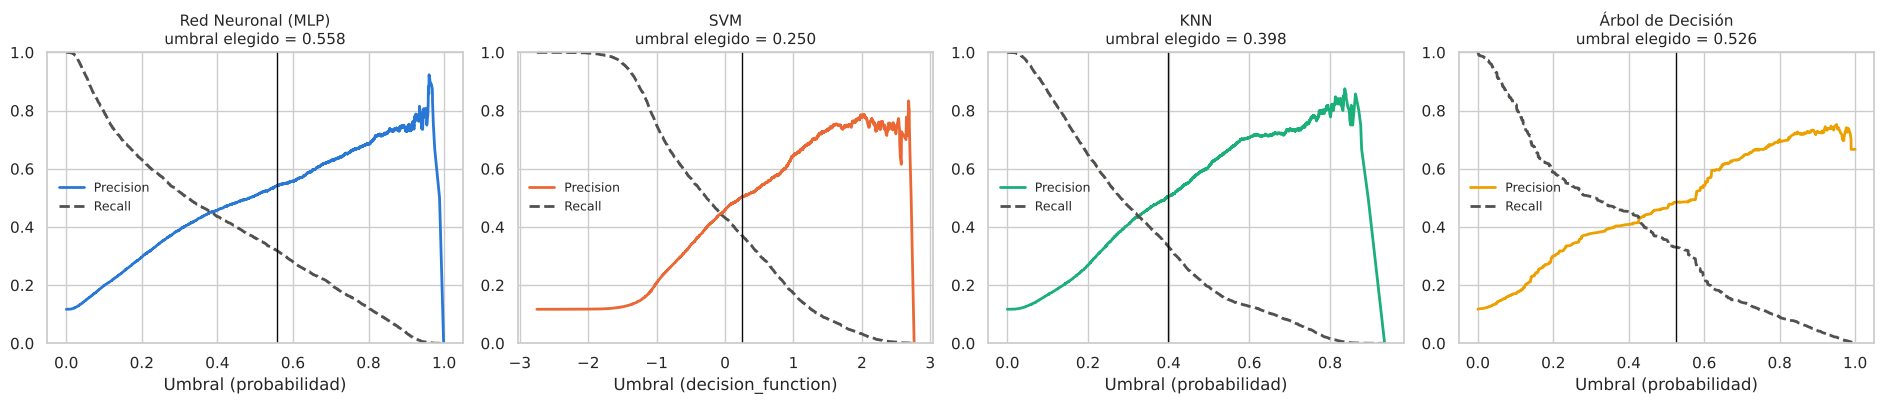

Valor  Precision  Recall     F1   F0.5  \
Modelo             Umbral                                                       
Red Neuronal (MLP) Umbral por defecto  0.500      0.508   0.363  0.423  0.471   
                   Umbral F0.5         0.558      0.542   0.320  0.402  0.476   
SVM                Umbral por defecto  0.000      0.459   0.431  0.445  0.453   
                   Umbral F0.5         0.250      0.504   0.371  0.427  0.470   
KNN                Umbral por defecto  0.500      0.609   0.194  0.294  0.426   
                   Umbral F0.5         0.398      0.505   0.337  0.404  0.459   
Árbol de Decisión  Umbral por defecto  0.500      0.464   0.356  0.403  0.437   
                   Umbral F0.5         0.526      0.486   0.330  0.393  0.444   

                                       % clientes marcados yes  
Modelo             Umbral                                       
Red Neuronal (MLP) Umbral por defecto                    8.342  
                   Umbral F0.5                           6.893  
SVM                Umbral por defecto                   10.996  
                   Umbral F0.5                           8.602  
KNN                Umbral por defecto                    3.730  
                   Umbral F0.5                           7.794  
Árbol de Decisión  Umbral por defecto                    8.975  
                   Umbral F0.5                           7.960

In [24]:
BETA = 0.5   # beta < 1 favorece la precision; con BETA = 1 se usa F1 (equilibrio precision-recall)

umbrales, filas_umbral = {}, []
fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
for ax, nombre in zip(axes, modelos):
    s = oof[nombre]
    prec, rec, thr = precision_recall_curve(y_train, s)
    prec, rec = prec[:-1], rec[:-1]
    fbeta = (1 + BETA**2) * prec * rec / (BETA**2 * prec + rec + 1e-12)
    umbrales[nombre] = float(thr[int(np.argmax(fbeta))])

    for etiqueta, u in [("Umbral por defecto", umbral_neutro(nombre)), (f"Umbral F{BETA}", umbrales[nombre])]:
        m = metricas_umbral(y_train, s, u)
        filas_umbral.append({"Modelo": nombre, "Umbral": etiqueta, "Valor": round(u, 3),
                             "Precision": m["Precision"], "Recall": m["Recall"], "F1": m["F1"],
                             f"F{BETA}": fbeta_score(y_train, (s >= u).astype(int), beta=BETA),
                             "% clientes marcados yes": (s >= u).mean() * 100})

    ax.plot(thr, prec, color=COLORES[nombre], lw=2, label="Precision")
    ax.plot(thr, rec, color="#52514e", lw=2, ls="--", label="Recall")
    ax.axvline(umbrales[nombre], color="#0b0b0b", lw=1)
    ax.set_title(f"{nombre}\numbral elegido = {umbrales[nombre]:.3f}", fontsize=11)
    ax.set_xlabel("Umbral" + (" (decision_function)" if nombre == "SVM" else " (probabilidad)"))
    ax.set_ylim(0, 1)
    ax.legend(frameon=False, fontsize=9, loc="center left")
plt.tight_layout()
plt.show()

display(pd.DataFrame(filas_umbral).set_index(["Modelo", "Umbral"]).round(3))

**Interpretación del umbral**
- El umbral sube en la Red Neuronal (0.558), la SVM (0.25 en la escala de la `decision_function`) y el Árbol (0.526): se exige más seguridad antes de marcar `yes` y la precision aumenta.
- En **KNN el umbral baja a 0.398**, porque con 0.5 el modelo era demasiado conservador: marcaba solo el 3.7 % de los clientes, con un recall de 0.19. Ajustarlo recupera recall (0.34) y mantiene la precision por encima de 0.50.
- Con su umbral, cada modelo selecciona entre el 7 % y el 9 % de los clientes para llamar.

## 14. Evaluación final en el 20 % de prueba: base vs. optimizado
Cada modelo optimizado se entrena con todo el 80 % y se evalúa una sola vez en el 20 % reservado, con el umbral por defecto y con el umbral F0.5 de la sección 13. Los resultados de los modelos base son los de la sección 10.

In [25]:
filas, puntajes_opt = [], {}
for nombre in modelos:
    filas.append({"Modelo": nombre, "Versión": "Base (umbral por defecto)",
                  **tabla_test.loc[nombre].to_dict()})
    pipe = clone(modelos_opt[nombre])
    inicio = time.time()
    pipe.fit(X_train, y_train)
    t_fit = time.time() - inicio
    s = puntaje(pipe, X_test)
    puntajes_opt[nombre] = s
    filas.append({"Modelo": nombre, "Versión": "Optimizado (umbral por defecto)",
                  **metricas_umbral(y_test, s, umbral_neutro(nombre)), "Tiempo de entrenamiento (s)": t_fit})
    filas.append({"Modelo": nombre, "Versión": f"Optimizado + umbral F{BETA} ({umbrales[nombre]:.3f})",
                  **metricas_umbral(y_test, s, umbrales[nombre]), "Tiempo de entrenamiento (s)": t_fit})
    print(f"{nombre:<20} evaluado")

tabla_test_opt = pd.DataFrame(filas).set_index(["Modelo", "Versión"])

Red Neuronal (MLP)   evaluado


SVM                  evaluado


KNN                  evaluado


Árbol de Decisión    evaluado


### 14.1 Tabla de desempeño en el 20 % de prueba

In [26]:
(tabla_test_opt.style
    .format({c: "{:.3f}" for c in LISTA_METRICAS} | {"Tiempo de entrenamiento (s)": "{:.1f}"})
    .apply(lambda fila: ["background-color: #d6e6f8" if "umbral F" in fila.name[1] else "" for _ in fila], axis=1)
    .set_caption("Conjunto de prueba: 9 043 clientes, 1 058 positivos. En azul, la versión final (optimizada + umbral F0.5)."))

### 14.2 Resumen de la mejora en ROC-AUC y precision

In [27]:
resumen = []
for nombre in modelos:
    base = tabla_test_opt.loc[(nombre, "Base (umbral por defecto)")]
    opt = tabla_test_opt.loc[(nombre, "Optimizado (umbral por defecto)")]
    fin = tabla_test_opt.loc[nombre].iloc[-1]
    resumen.append({"Modelo": nombre,
                    "ROC-AUC base": base["ROC-AUC"], "ROC-AUC optimizado": opt["ROC-AUC"],
                    "Δ ROC-AUC": opt["ROC-AUC"] - base["ROC-AUC"],
                    "Precision base": base["Precision"], "Precision final": fin["Precision"],
                    "Δ Precision": fin["Precision"] - base["Precision"],
                    "Recall base": base["Recall"], "Recall final": fin["Recall"],
                    "F1 base": base["F1"], "F1 final": fin["F1"]})
display(pd.DataFrame(resumen).set_index("Modelo").round(3))

,ROC-AUC base,ROC-AUC optimizado,Δ ROC-AUC,Precision base,Precision final,Δ Precision,Recall base,Recall final,F1 base,F1 final
Modelo,,,,,,,,,,
Red Neuronal (MLP),0.771,0.788,0.016,0.424,0.568,0.144,0.465,0.352,0.444,0.434
SVM,0.768,0.771,0.003,0.463,0.525,0.062,0.467,0.387,0.465,0.445
KNN,0.775,0.782,0.007,0.398,0.516,0.117,0.469,0.342,0.431,0.411
Árbol de Decisión,0.761,0.766,0.005,0.363,0.483,0.120,0.528,0.338,0.430,0.398


### 14.3 Curvas ROC: base vs. optimizado (prueba)

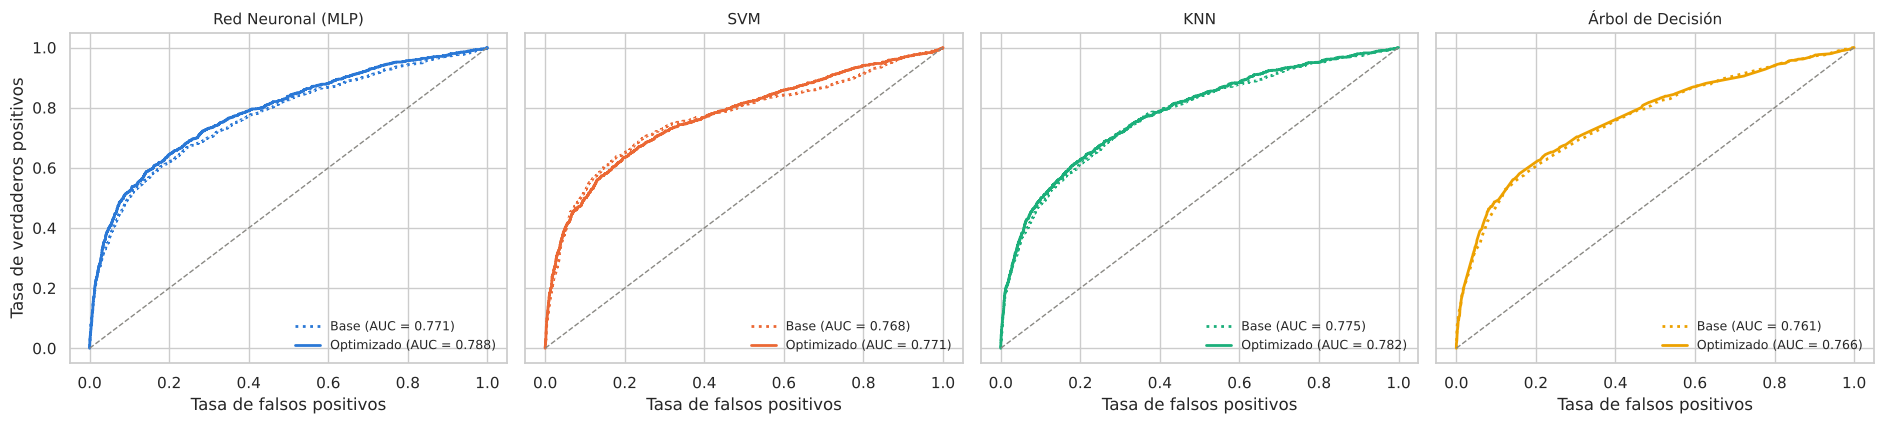

In [28]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.4), sharey=True)
for ax, nombre in zip(axes, modelos):
    for version, s, estilo in [("Base", puntajes[nombre], ":"), ("Optimizado", puntajes_opt[nombre], "-")]:
        fpr, tpr, _ = roc_curve(y_test, s)
        ax.plot(fpr, tpr, ls=estilo, lw=2, color=COLORES[nombre],
                label=f"{version} (AUC = {roc_auc_score(y_test, s):.3f})")
    ax.plot([0, 1], [0, 1], ls="--", lw=1, color="#8a8984")
    ax.set_title(nombre, fontsize=11)
    ax.set_xlabel("Tasa de falsos positivos")
    ax.legend(frameon=False, fontsize=9, loc="lower right")
axes[0].set_ylabel("Tasa de verdaderos positivos")
plt.tight_layout()
plt.show()

### 14.4 Matrices de confusión de la versión final (optimizado + umbral F0.5)

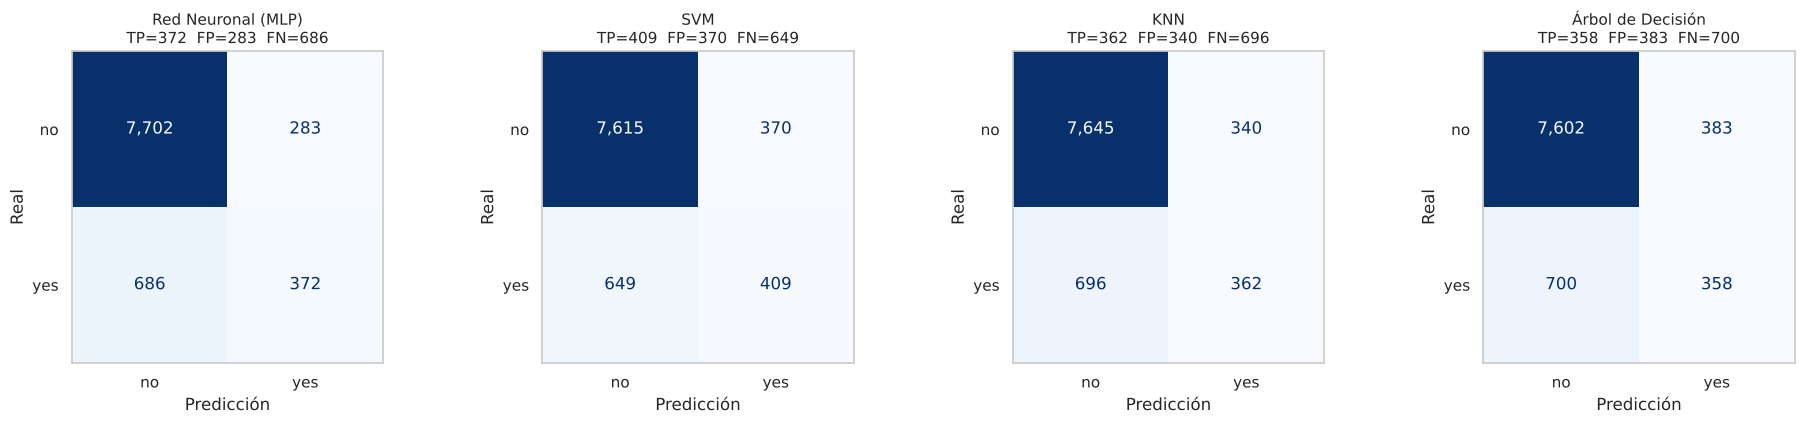

In [29]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.3))
for ax, nombre in zip(axes, modelos):
    cm = confusion_matrix(y_test, (puntajes_opt[nombre] >= umbrales[nombre]).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["no", "yes"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=",")
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f"{nombre}\nTP={tp:,}  FP={fp:,}  FN={fn:,}", fontsize=11)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Real")
    ax.grid(False)
plt.tight_layout()
plt.show()

**Interpretación de la evaluación final**

**ROC-AUC (área bajo la curva): mejora en los 4 modelos**, y la mejora se confirma en datos que nunca se usaron para optimizar.

| Modelo | ROC-AUC base | ROC-AUC optimizado |
|---|---|---|
| Red Neuronal | 0.771 | **0.788** (la mayor) |
| KNN | 0.775 | 0.782 |
| SVM | 0.768 | 0.771 |
| Árbol | 0.761 | 0.766 |

**Precision: sube entre 6 y 14 puntos porcentuales.**

| Modelo | Precision base | Precision final |
|---|---|---|
| Red Neuronal | 0.424 | **0.568** |
| SVM | 0.463 | 0.525 |
| KNN | 0.398 | 0.516 |
| Árbol | 0.363 | 0.483 |

En términos de negocio, la Red Neuronal optimizada recomienda llamar a 655 clientes, de los cuales 372 contratan (57 %). La versión base recomendaba 1 160 llamadas con 492 contrataciones (42 %). Es casi 5 veces la tasa de éxito de llamar al azar (11.7 %).

**El costo es el recall.** Los modelos finales detectan entre el 34 % y el 39 % de los clientes que contratan, frente al 47–53 % de los base, y el F1 queda similar o un poco menor (0.40–0.45). Es el intercambio esperado al priorizar la precision: menos llamadas, más efectivas, pero se dejan pasar más clientes potenciales. Si se prefiere detectar más clientes, basta con usar `BETA = 1` en la sección 13.

**La mejora propia del modelo es la de ROC-AUC y PR-AUC.** La de precision viene sobre todo de mover el punto de operación (menos SMOTE y otro umbral).

Una opción intermedia es la Red Neuronal optimizada con el umbral por defecto: precision de 0.540, recall de 0.386 y el mejor F1 de los modelos optimizados (0.450).

**Desempeño moderado en general:** sin `duration`, las variables disponibles antes de la llamada separan las clases solo parcialmente (ROC-AUC ≈ 0.77–0.79). Es una consecuencia del planteamiento antes de la llamada, que es el realista para el negocio.

## 15. Conclusiones
1. Se implementaron los 4 modelos supervisados (Red Neuronal, SVM, KNN y Árbol de Decisión) con un flujo libre de fuga de información: partición estratificada 80/20 → SMOTE-NC solo dentro del entrenamiento → validación cruzada estratificada de 10 folds → evaluación única en el 20 % reservado.
2. Con las configuraciones base, los 4 modelos superan ampliamente a la línea base. Ranking por F1 en prueba: **SVM (0.465) > Red Neuronal (0.444) > KNN (0.431) ≈ Árbol (0.430)**.
3. Hiperparámetros optimizados (criterio ROC-AUC) y umbral elegido (F0.5):

   | Modelo | Hiperparámetros | Umbral |
   |---|---|---|
   | Red Neuronal | capas (64, 32), `alpha` = 0.1, `learning_rate_init` = 0.001, SMOTE 0.25 | 0.558 |
   | SVM | RBF con `C` = 0.3, `gamma` = 0.03, SMOTE 0.5 | 0.25 (`decision_function`) |
   | KNN | k = 301, `weights` = "distance", distancia Manhattan (`p` = 1), SMOTE 0.25 | 0.398 |
   | Árbol | gini, `max_depth` = 10, `min_samples_leaf` = 50, SMOTE 0.25 | 0.526 |

4. La **proporción del SMOTE** fue el hiperparámetro más influyente: un balanceo más moderado (0.25) mejora la ROC-AUC y la precision en tres de los cuatro modelos.
5. En prueba, la **ROC-AUC mejoró en los 4 modelos** (hasta 0.788 en la Red Neuronal) y la **precision subió entre 6 y 14 puntos**, a cambio de un menor recall. La **Red Neuronal optimizada** es la mejor en ambas métricas objetivo.